In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

a = pd.read_excel('AssessmentDataScientist.xlsx', sheet_name='Application Data')
l = pd.read_excel('AssessmentDataScientist.xlsx', sheet_name='Loan Performance')

a['customer_id'] = a.customer_id.str.lower()
l['customer_id'] = l.idLoan.str[:-3].str.lower()
l['loan_no'] = l.idLoan.str[-2:]
l['bad'] = (l.flgGood == 'Bad').astype(int)

df = a.merge(l, on='customer_id', how='inner')

print("Applications:", a.shape)
print("Loans:", l.shape)
print("Joined:", df.shape)
print("Overall bad rate:", round(df.bad.mean(), 3))

Applications: (647, 31)
Loans: (1285, 5)
Joined: (650, 35)
Overall bad rate: 0.543


c:\Users\kumar\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\kumar\AppData\Local\Programs\Python\Python311\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [5]:
# 1. Only taking the first loan for each customer
df = df[df.loan_no == '01'].copy()
print("Rows after keeping first loan:", df.shape)

# 2. New numeric features
df['age'] = (df.application_when - df.birth_date).dt.days / 365.25
df['rent_to_income'] = df.monthly_rent_amount / df.monthly_income_amount
df['payment_to_income'] = df.payment_amount / df.monthly_income_amount
df['approved_ratio'] = df.amount_approved / df.amount_requested
df['has_other_phone'] = df.other_phone_type.notna().astype(int)

# 3. Changing the text columns of duration into ordered numbers
dur = {'6 months or less': 0, '7-12 months': 1, '1-2 years': 2, '3+ years': 3}
df['residence_dur_n'] = df.residence_duration.map(dur)
df['bank_dur_n'] = df.bank_account_duration.map(dur)
df['email_dur_n'] = df.email_duration.map(
    {'3 months or less': 0, '4-12 months': 1, '1 year or more': 2})

# 4. Month column
df['app_month'] = df.application_when.dt.to_period('M')

# 5. Quick check
print(df[['age', 'rent_to_income', 'payment_to_income', 'approved_ratio']].describe().round(2))
print()
print("Missing values:")
print(df.isna().sum()[lambda s: s > 0])
print()
print("Bad rate by application month:")
print(df.groupby('app_month').bad.agg(['mean', 'count']).round(3))

Rows after keeping first loan: (634, 44)
          age  rent_to_income  payment_to_income  approved_ratio
count  634.00          634.00             634.00          634.00
mean    42.56            0.24               0.06            0.91
std     12.34            0.18               0.05            0.15
min     18.08            0.00               0.00            0.62
25%     32.75            0.13               0.03            0.83
50%     41.66            0.24               0.05            1.00
75%     51.33            0.35               0.07            1.00
max     79.78            1.14               0.57            1.00

Missing values:
payment_amount_approved     20
bank_account_duration        1
other_phone_type           280
how_use_money                2
bank_dur_n                   1
dtype: int64

Bad rate by application month:
            mean  count
app_month              
2010-10    0.688     16
2010-11    0.661     56
2010-12    0.556     81
2011-01    0.611    108
2011-02    0.

In [ ]:
# Correlation of numeric features with the target variable
num = ['age', 'monthly_income_amount', 'rent_to_income', 'payment_to_income',
       'amount_requested', 'amount_approved', 'approved_ratio', 'num_payments',
       'payment_amount', 'residence_dur_n', 'bank_dur_n', 'email_dur_n',
       'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail',
       'raw_FICO_bank_card', 'raw_FICO_money']

corr = df[num + ['bad']].corr()['bad'].drop('bad').sort_values()
print(corr.round(3))

raw_FICO_retail         -0.178
age                     -0.156
raw_FICO_telecom        -0.156
raw_FICO_bank_card      -0.156
raw_FICO_money          -0.149
payment_amount          -0.145
bank_dur_n              -0.109
approved_ratio          -0.091
payment_to_income       -0.082
residence_dur_n         -0.052
amount_approved         -0.032
rent_to_income          -0.020
monthly_income_amount   -0.017
email_dur_n              0.021
raw_l2c_score            0.023
amount_requested         0.043
num_payments             0.103
Name: bad, dtype: float64


In [7]:
# Bad rate by groups (numeric features)
def bad_rate_by_bins(col, q=5):
    t = df.groupby(pd.qcut(df[col], q, duplicates='drop'), observed=True).bad.agg(['mean', 'count'])
    return t.round(3)

for c in ['raw_FICO_retail', 'age', 'monthly_income_amount', 'payment_to_income']:
    print(c)
    print(bad_rate_by_bins(c))
    print()

raw_FICO_retail
                   mean  count
raw_FICO_retail               
(221.999, 550.0]  0.718    131
(550.0, 578.2]    0.520    123
(578.2, 612.8]    0.603    126
(612.8, 644.0]    0.515    132
(644.0, 756.0]    0.393    122

age
                               mean  count
age                                       
(18.073999999999998, 30.985]  0.622    127
(30.985, 38.871]              0.606    127
(38.871, 45.159]              0.587    126
(45.159, 53.372]              0.520    127
(53.372, 79.778]              0.425    127

monthly_income_amount
                        mean  count
monthly_income_amount              
(299.999, 1400.0]      0.536    138
(1400.0, 2000.0]       0.595    126
(2000.0, 2600.0]       0.556    126
(2600.0, 3500.0]       0.585    123
(3500.0, 19392.0]      0.488    121

payment_to_income
                                  mean  count
payment_to_income                            
(0.0031799999999999997, 0.0271]  0.543    127
(0.0271, 0.0391]             

In [9]:
# Bad rate by category(text/boolean features)
for c in ['payment_frequency', 'bank_account_direct_deposit', 'residence_rent_or_own',
          'bank_account_duration', 'home_phone_type']:
    print(df.groupby(c).bad.agg(['mean', 'count']).round(3))
    print()

                    mean  count
payment_frequency              
Bi-weekly          0.636    324
Monthly            0.441    170
Semi-monthly       0.416    113
Weekly             0.815     27

                              mean  count
bank_account_direct_deposit              
False                        0.627    118
True                         0.535    516

                        mean  count
residence_rent_or_own              
False                  0.488    209
True                   0.584    425

                        mean  count
bank_account_duration              
1-2 years              0.594    128
3+ years               0.500    320
6 months or less       0.654    130
7-12 months            0.509     55

                  mean  count
home_phone_type              
Home             0.477    109
Mobile           0.567    515
Work             0.600     10



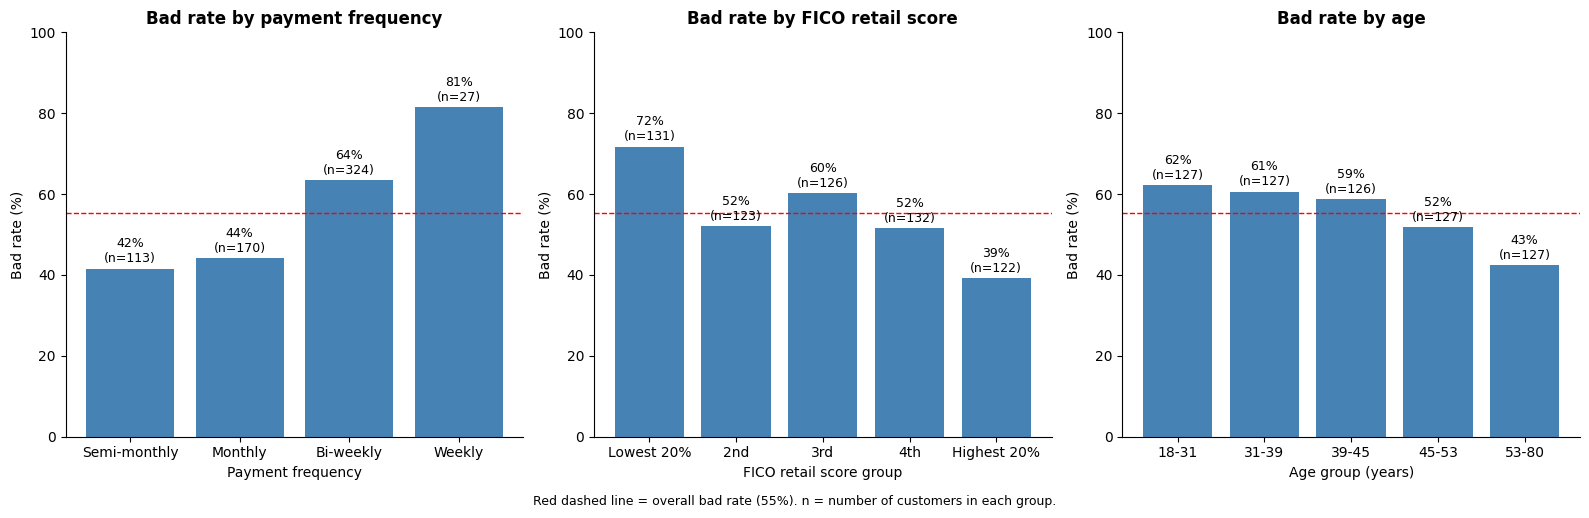

In [29]:

def bar_chart(ax, g, title, xlabel):
    rate = g.mean() * 100
    n = g.count()
    bars = ax.bar(range(len(rate)), rate.values, color='steelblue')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels(rate.index, rotation=0)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Bad rate (%)')
    ax.set_ylim(0, 100)
    ax.axhline(df.bad.mean() * 100, color='red', ls='--', lw=1)
    for b, r, c in zip(bars, rate.values, n.values):
        ax.text(b.get_x() + b.get_width() / 2, r + 1.5, f'{r:.0f}%\n(n={c})',
                ha='center', fontsize=9)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# 1. Payment frequency (logical order mein)
order = ['Semi-monthly', 'Monthly', 'Bi-weekly', 'Weekly']
g1 = df.groupby(pd.Categorical(df.payment_frequency, categories=order, ordered=True),
                observed=True).bad
bar_chart(ax[0], g1, 'Bad rate by payment frequency', 'Payment frequency')

# 2. FICO retail
labels5 = ['Lowest 20%', '2nd', '3rd', '4th', 'Highest 20%']
fico = pd.qcut(df.raw_FICO_retail, 5, labels=labels5)
bar_chart(ax[1], df.groupby(fico, observed=True).bad,
          'Bad rate by FICO retail score', 'FICO retail score group')

# 3. Age
age = pd.qcut(df.age, 5, labels=['18-31', '31-39', '39-45', '45-53', '53-80'])
bar_chart(ax[2], df.groupby(age, observed=True).bad,
          'Bad rate by age', 'Age group (years)')

fig.text(0.5, -0.02,
         'Red dashed line = overall bad rate (55%). n = number of customers in each group.',
         ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('chart_bad_rate.png', dpi=150, bbox_inches='tight')   # slides ke liye save
plt.show()

In [30]:
# Model creation and evaluation

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

df['has_other_phone'] = df.other_phone_type.notna().astype(int)  # agar pehle nahi banaya

num = ['age', 'monthly_income_amount', 'rent_to_income', 'payment_to_income',
       'amount_requested', 'approved_ratio', 'num_payments', 'payment_amount',
       'residence_dur_n', 'bank_dur_n', 'email_dur_n', 'has_other_phone',
       'raw_l2c_score', 'raw_FICO_telecom', 'raw_FICO_retail',
       'raw_FICO_bank_card', 'raw_FICO_money']

X = df[num].copy()
X['rent_own'] = df.residence_rent_or_own.astype(int)
X['direct_deposit'] = df.bank_account_direct_deposit.astype(int)
X = pd.concat([X, pd.get_dummies(df.payment_frequency, prefix='freq').astype(int)], axis=1)
y = df.bad.values
print(X.shape)

(634, 23)


In [31]:
# Comparing two models: Logistic regression and Gradient Boosting Classifier

cv = StratifiedKFold(5, shuffle=True, random_state=42)

def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

models = {
    'Logistic': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                              LogisticRegression(C=0.1, max_iter=1000)),
    'GradBoost': make_pipeline(SimpleImputer(strategy='median'),
                               GradientBoostingClassifier(n_estimators=100, max_depth=2,
                                                          learning_rate=0.05, subsample=0.8,
                                                          random_state=42)),
}

for name, m in models.items():
    p = cross_val_predict(m, X, y, cv=cv, method='predict_proba')[:, 1]
    print(name, 'AUC', round(roc_auc_score(y, p), 3), 'KS', round(ks(y, p), 3))

print("Company's own l2c score alone, AUC:", round(roc_auc_score(y, df.raw_l2c_score), 3))

Logistic AUC 0.665 KS 0.272
GradBoost AUC 0.64 KS 0.235
Company's own l2c score alone, AUC: 0.473


In [32]:
# Model coefficients for Logistic Regression

m = models['Logistic'].fit(X, y)
coef = pd.Series(m[-1].coef_[0], index=X.columns).sort_values()
print(coef.round(3))

raw_FICO_retail         -0.329
num_payments            -0.281
freq_Semi-monthly       -0.245
age                     -0.225
payment_amount          -0.215
direct_deposit          -0.160
raw_FICO_bank_card      -0.097
freq_Monthly            -0.096
bank_dur_n              -0.068
rent_to_income          -0.037
payment_to_income       -0.016
approved_ratio           0.001
residence_dur_n          0.021
email_dur_n              0.021
monthly_income_amount    0.029
raw_l2c_score            0.043
raw_FICO_money           0.046
rent_own                 0.065
raw_FICO_telecom         0.091
has_other_phone          0.114
freq_Bi-weekly           0.149
amount_requested         0.210
freq_Weekly              0.306
dtype: float64


In [ ]:
# Making Cutoff 

# Every customer risk score calculation

model = models['Logistic']
df['p_bad'] = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]

# 10 barabar groups (deciles): 1 = sabse safe, 10 = sabse risky
df['decile'] = pd.qcut(df.p_bad.rank(method='first'), 10, labels=range(1, 11))
dt = df.groupby('decile', observed=True).agg(
    customers=('bad', 'size'), bad_rate=('bad', 'mean'), avg_p_bad=('p_bad', 'mean')).round(3)
print(dt)

        customers  bad_rate  avg_p_bad
decile                                
1              64     0.281      0.272
2              63     0.286      0.372
3              63     0.508      0.431
4              64     0.500      0.484
5              63     0.587      0.534
6              63     0.587      0.580
7              64     0.672      0.625
8              63     0.730      0.669
9              63     0.714      0.723
10             64     0.656      0.807


In [34]:
# Cutoff table for different approval percentages

d = df.sort_values('p_bad').reset_index(drop=True)
rows = []
for ap in [100, 90, 80, 70, 60, 50, 40, 30]:
    k = int(len(d) * ap / 100)
    s = d.iloc[:k]
    rows.append((ap, k, round(s.bad.mean(), 3), int((1 - s.bad).sum()),
                 int(s.bad.sum()), round(d.p_bad.iloc[k - 1], 3)))

cutoff = pd.DataFrame(rows, columns=['approve_%', 'approved', 'bad_rate', 'good_loans',
                                     'bad_loans', 'score_cutoff'])
print(cutoff)

   approve_%  approved  bad_rate  good_loans  bad_loans  score_cutoff
0        100       634     0.552         284        350         0.998
1         90       570     0.540         262        308         0.753
2         80       507     0.519         244        263         0.692
3         70       443     0.490         226        217         0.645
4         60       380     0.458         206        174         0.603
5         50       317     0.432         180        137         0.557
6         40       253     0.391         154         99         0.508
7         30       190     0.358         122         68         0.460


Break-even p_bad: 0.167
Best cutoff: approve top 4 of 634 = 1 %
Total profit at best cutoff: -160  vs approve-all: -117280


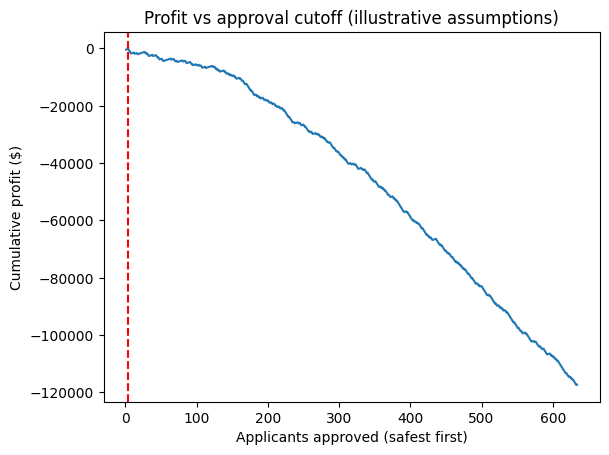

In [36]:
# ASSUMPTIONS: inhe badal sakte ho
profit_good = 80     # ek good loan se kamai (fee + interest), $
loss_bad = 400       # ek bad loan se nuksaan, $

d['profit'] = np.where(d.bad == 0, profit_good, -loss_bad)
d['cum_profit'] = d.profit.cumsum()
best = d.cum_profit.idxmax()
print("Break-even p_bad:", round(profit_good / (profit_good + loss_bad), 3))
print("Best cutoff: approve top", best + 1, "of", len(d), "=", round((best + 1) / len(d) * 100), "%")
print("Total profit at best cutoff:", d.cum_profit.max(), " vs approve-all:", d.profit.sum())

plt.plot(range(1, len(d) + 1), d.cum_profit)
plt.axvline(best + 1, color='red', ls='--')
plt.xlabel('Applicants approved (safest first)'); plt.ylabel('Cumulative profit ($)')
plt.title('Profit vs approval cutoff (illustrative assumptions)')
plt.show()

In [37]:
# Time-based stability check

cut = pd.Timestamp('2011-02-01')
tr = (df.application_when < cut).values
te = ~tr
print('train', tr.sum(), 'test', te.sum())
print('bad rate train', round(df.bad[tr].mean(), 3), 'test', round(df.bad[te].mean(), 3))

# Logistic: Only on old data, test on new data 
m = models['Logistic'].fit(X[tr], y[tr])
pt = m.predict_proba(X[te])[:, 1]
print('Time-split AUC', round(roc_auc_score(y[te], pt), 3), 'KS', round(ks(y[te], pt), 3))

# Comparing Gradient Boosting Classifier with Logistic Regression on time-split data
mg = models['GradBoost'].fit(X[tr], y[tr])
pg = mg.predict_proba(X[te])[:, 1]
print('GradBoost time-split AUC', round(roc_auc_score(y[te], pg), 3))

# Bootstrap confidence interval (AUC stability check) 
rng = np.random.default_rng(0)
yt = y[te]
aucs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() != yt[i].max():
        aucs.append(roc_auc_score(yt[i], pt[i]))
print('Time-split AUC 95% CI', np.percentile(aucs, [2.5, 97.5]).round(3))

# Test period of cutoff table
t = pd.DataFrame({'p': pt, 'bad': yt}).sort_values('p').reset_index(drop=True)
for ap in [100, 70, 50, 30]:
    k = int(len(t) * ap / 100)
    print(f'Approve {ap}%: n={k}, bad rate={t.bad.iloc[:k].mean():.3f}')

train 261 test 373
bad rate train 0.609 test 0.512
Time-split AUC 0.588 KS 0.193
GradBoost time-split AUC 0.626
Time-split AUC 95% CI [0.525 0.648]
Approve 100%: n=373, bad rate=0.512
Approve 70%: n=261, bad rate=0.490
Approve 50%: n=186, bad rate=0.468
Approve 30%: n=111, bad rate=0.378
